# Create a water-sphere phantom

This notebook is at `docs/tutorials/water-phantom.ipynb`.
[View notebook](water-phantom.ipynb) or download
{download}`water-phantom.ipynb <water-phantom.ipynb>`.

This example defines a phantom in PSF, runs small pilot batches for a chosen species list, and explores the resulting responses and uncertainties. Further sampling can continue from the terminal.

[Building phantoms](../running-atris/build-phantoms.md) describes refinement, precision targets, and recovery. These small batches illustrate the workflow; further sampling improves the precision.

## 1. Run directory

The example writes its files alongside the notebook, using relative filenames. These filenames can also include a path to another folder.

In [1]:
import logging
import matplotlib.pyplot as plt
from atris_tools.psf import PSF
from atris_tools.phantom_builder import PhantomBuilder
from atris_tools.phantom_calibration import Phantom
from atris_tools.phantom_diagnostics import plot_creation_diagnostics, plot_sampling_precision

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")

## 2. Water sphere

Water is the material chosen for this example. The sampling builder preserves spherical PSF layers and their materials. The innermost layer is the detector; outer layers are passive shielding. This example has no shielding.

The arguments to `PSF` specify radii in km, temperature in K, density in $\mathrm{g/cm^3}$ and pressure in Pa. Here, 15 cm is $1.5\times10^{-4}$ km.

Water has two hydrogen atoms per oxygen atom. Their molar masses determine the hydrogen and oxygen mass fractions calculated below.

The beam uniformly illuminates the projected disk. For an unshielded sphere, rotational symmetry makes this equivalent to averaging over incoming directions. The exported effective area is $2\pi r^2$, for AtRIS's two-direction interface-crossing normalization.

The builder expands the physical PSF with vacuum termination shells, assigns the scoring IDs, and uses the ordinary PSF-to-GDML converter with a world sized for this sphere. The physical PSF retains the sphere's dimensions and material.

In [2]:
hydrogen_molar_mass = 1.00794
oxygen_molar_mass = 15.9994
water_molar_mass = 2 * hydrogen_molar_mass + oxygen_molar_mass
water_mass_fractions = {
    "H": 2 * hydrogen_molar_mass / water_molar_mass,
    "O": oxygen_molar_mass / water_molar_mass,
}

sphere = PSF(
    inner_radius_km=0, outer_radius_km=1.5e-4,
    temperature_k=293, density_g_cm3=0.997,
    pressure_pa=101325, state="liquid",
    mass_fractions=water_mass_fractions,
)
print(sphere)

PSF: 1 spherical layer
Radii (km); density (g/cm3); temperature (K); pressure (Pa)
Layer 0: 0.000000e+00 to 1.500000e-04; liquid; density=9.970000e-01; temperature=2.930000e+02; pressure=1.013250e+05; mass fractions: H=1.118983e-01, O=8.881017e-01


## 3. Species and sampling settings

`species` selects the incident particles and isotopes. The API resolves their names to identifiers and uses fully stripped nuclei. Photons occupy the first row of the exported AtRIS table. `pilot_events` sets the event ceiling for each initial full-range batch. The large ceiling below lets sampling reach the native 60-second time limit. Histograms retain the actual number of completed primaries.

Species accept particle names and isotope forms such as `Fe-56`, `iron-56`, `(26, 56)` or `("Fe", 56)`.

`production_cut_mm` sets Geant4's secondary-production range cut in millimetres. Geant4 converts this length into material-dependent energy thresholds. For processes using these cuts, energy transfers below the threshold contribute to local deposition; higher transfers create secondary particles whose transport is followed explicitly.

The example's 0.1 mm cut is small compared with its 150 mm sphere radius. For a micrometre-sized sphere, the same cut can replace transport over distances comparable to the sphere with local deposition, affecting how much energy escapes. A suitable cut is established by reducing it until the response curves agree within sampling uncertainty; [production cuts and phantom size](../running-atris/build-phantoms.md#production-cuts-and-phantom-size) explains this check.

Counting records strictly positive ionizing deposits. The relative tolerance and absolute dose tolerance define the refinement target; the builder compares its confidence-scaled standard error with that target. These settings are editable in the following cell.

In [3]:
name = "water-sphere"
species = ["photon", "proton", "iron-56", "nickel-58"]

builder = PhantomBuilder(
    sphere, species,
    name=name,
    pilot_events=100_000_000,
    production_cut_mm=0.1, dose_rtol=0.05, dose_atol_Gy=1e-12,
)
print(builder)

Phantom sampling: water-sphere
Species: photon, proton, Fe-56, Ni-58
Primaries per pilot: photon 1.000e+08, proton 1.000e+08, Fe-56 1.000e+08, Ni-58 1.000e+08
Production cut: 0.1 mm
Relative dose tolerance: 5.0%
Absolute dose tolerance: 1.0e-12 Gy


The sampling plan lists upcoming species, incident kinetic-energy ranges, primary counts and selection reasons. Initial batches say "initial coverage". Refinement distinguishes "insufficient samples", "unresolved uncertainty", "zero deposit" and "timing pilot". Later selections say "coverage" for periodic coverage turns or "precision" for predicted uncertainty reduction per second. The preview predicts the requested batches from the current statistics. Actual adaptive choices are recalculated as new results arrive.

`schedule` retains the displayed batch records for inspection: for example, `schedule[0].species`, `schedule[0].energy_range_MeV` and `schedule[0].events`. Without `batches`, both preview and execution default to one batch.

In [4]:
schedule = builder.show_schedule(batches=4, adaptive=True, time_limit_s=60)

Schedule preview: 4 batches
Batch  Species  K min (MeV)  K max (MeV)  Primaries  Reason            Status 
1      photon   1.000e-06    1.000e+07    1.000e+08  initial coverage  planned
2      proton   1.000e-06    1.000e+07    1.000e+08  initial coverage  planned
3      Fe-56    1.000e-06    1.000e+07    1.000e+08  initial coverage  planned
4      Ni-58    1.000e-06    1.000e+07    1.000e+08  initial coverage  planned
Preview uses current statistics; actual choices are recalculated after each batch.


## 4. Pilot transport

`PhantomBuilder(...)` saves the sampling settings in the current folder. `builder.run(...)` executes batches and logs the folder, sampling settings and equivalent `atris-build-phantom` command for continuing from the terminal. The command opens the same builder settings from that folder.

The builder first samples each configured species across the energy range. Further invocations add batches; interrupted inputs resume first.

In [5]:
phantom = builder.run(batches=4, threads=3, adaptive=True, time_limit_s=60)

INFO Running phantom sampling in folder /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9


INFO Batches: 4; transport threads per batch: 3


INFO Equivalent terminal command: atris-build-phantom . --batches 4 --threads 3 --adaptive


INFO Simulating up to 1.000e+08 primaries of photon (PDG 22) with kinetic energies from 1.000e-06 to 1.000e+07 MeV to sample this species across the full energy range.


INFO Starting AtRIS chunked run
INFO Run directory: /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9/batches/batch-000000
INFO Chunk plan: /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9/batches/batch-000000/chunks.txt
INFO Physics list: FTFP_BERT_HP
INFO Output mode: phantom (3)
INFO Processing 1 chunks...
INFO 0/1 chunks already processed
INFO Processing remaining 1/1 chunk...


...

INFO Starting AtRIS chunked run
INFO Run directory: /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9/batches/batch-000002
INFO Chunk plan: /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9/batches/batch-000002/chunks.txt
INFO Physics list: FTFP_BERT_HP
INFO Output mode: phantom (3)
INFO Processing 1 chunks...
INFO 0/1 chunks already processed
INFO Processing remaining 1/1 chunk...


INFO Chunk 1/1 complete in 1.0 min. ETA: 0.0 min
INFO AtRIS chunk run finished
INFO Completed 1 new chunk in 1.0 min
INFO Finished chunks: 1/1
INFO Remaining: 0 chunks


INFO Simulating up to 1.000e+08 primaries of Ni-58 (PDG 1000280580) with kinetic energies from 1.000e-06 to 1.000e+07 MeV to sample this species across the full energy range.


INFO Starting AtRIS chunked run
INFO Run directory: /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9/batches/batch-000003
INFO Chunk plan: /Users/dagfev/Documents/starwinds/ATRIS/tmp/phantom-one-minute-notebook-g6ds1av9/batches/batch-000003/chunks.txt
INFO Physics list: FTFP_BERT_HP
INFO Output mode: phantom (3)
INFO Processing 1 chunks...
INFO 0/1 chunks already processed
INFO Processing remaining 1/1 chunk...


INFO Chunk 1/1 complete in 1.0 min. ETA: 0.0 min
INFO AtRIS chunk run finished
INFO Completed 1 new chunk in 1.0 min
INFO Finished chunks: 1/1
INFO Remaining: 0 chunks


## 5. Completed statistics

The following cell reads completed chunks and refreshes the exports. Missing estimates are represented by NaN. After further terminal batches, this cell provides an updated view of the results.

In [6]:
phantom = Phantom.gather(name)
print(phantom)
paths = phantom.save()

water-sphere: radius 15 cm, density 0.997 g/cm^3
Incident species: 4
Primaries retained: 4,579,108
Sampled bins: 2,600/2,600
Resolved energy bins: 2,600
Passing energy bins: 2,322
Precision complete: False


## 6. View the phantom results

Each curve represents one species: particles in the left column and nuclei in the right.

The pilot batches spread a small number of primaries over many energy bins. Some bins therefore have few samples or none yet, producing irregular curves and gaps. Gathering again after additional batches updates the plotted responses and their uncertainties.

$W$ is the ionizing energy deposited by a primary and its secondaries; $K$ is that primary's incident kinetic energy:

$$
\left\langle\frac{W}{K}\right\rangle.
$$

The average includes zero-deposit primaries. Values above one can result from rest energy released by annihilation, decay, or reactions.

The top row shows how much ionizing energy the sphere receives relative to the incoming kinetic energy. For example, a value of $0.1$ means an average deposited fraction of 10% in that bin. The black line at one marks deposition equal to the incident kinetic energy. The diagonal guides express the same response as dose per primary, using this sphere's mass and the energy-bin centres.

The bottom row shows how precisely each mean fraction has been estimated: its standard error divided by the magnitude of the mean. A value of $0.01$ means a one-standard-error uncertainty of 1% on the mean, rather than a 1% spread in individual deposits. The percentage guides make it easier to identify energy ranges that need more sampling. The adaptive builder compares a confidence-scaled standard error with the configured relative and absolute dose tolerances.

The logarithmic plots show positive, finite estimates. Unresolved bins and zero estimated errors remain available in the stored arrays.

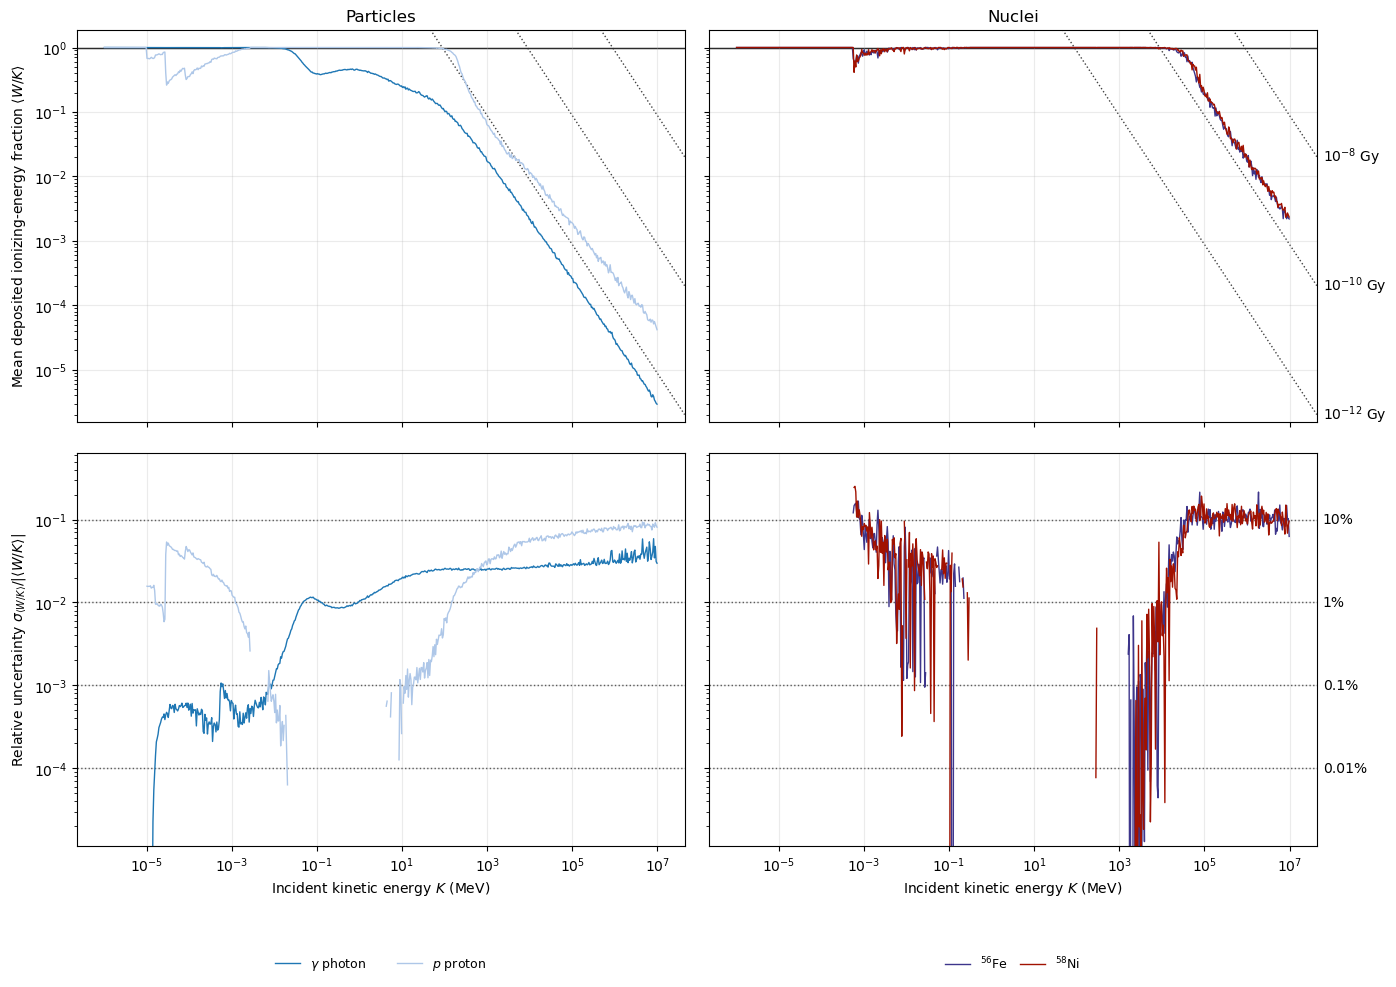

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, sharey="row")
plot_creation_diagnostics(phantom, axes=axes)
fig.subplots_adjust(bottom=0.2, right=0.9, hspace=0.08, wspace=0.04)
plt.show()

## 7. Reaching the desired precision

The uncertainty maps below help identify where further sampling is needed. The relative uncertainty describes precision compared with the mean response; the absolute dose uncertainty relates it to the dose tolerance chosen earlier. Together they show why the builder uses both relative and absolute tolerances.

Every map has incident energy along the horizontal axis and one species per row. The top-left map shows relative response uncertainty; the top-right shows absolute dose uncertainty in Gy per primary for this sphere. Both use one standard error. Blue indicates smaller uncertainty and red larger uncertainty. The colour-bar triangles indicate values outside the displayed range; grey indicates bins without a usable uncertainty estimate. The builder applies the configured confidence factor when comparing these estimates with its precision target.

The bottom-left map shows the number of incident primaries sampled in each bin, including those depositing no energy. The bottom-right shows the number counted through a positive ionizing deposit. These are primary counts, not secondary-particle counts. Both use the same logarithmic colour scale; grey marks zero counts. This distinguishes a sparsely sampled bin from a well-sampled bin with few depositing events.

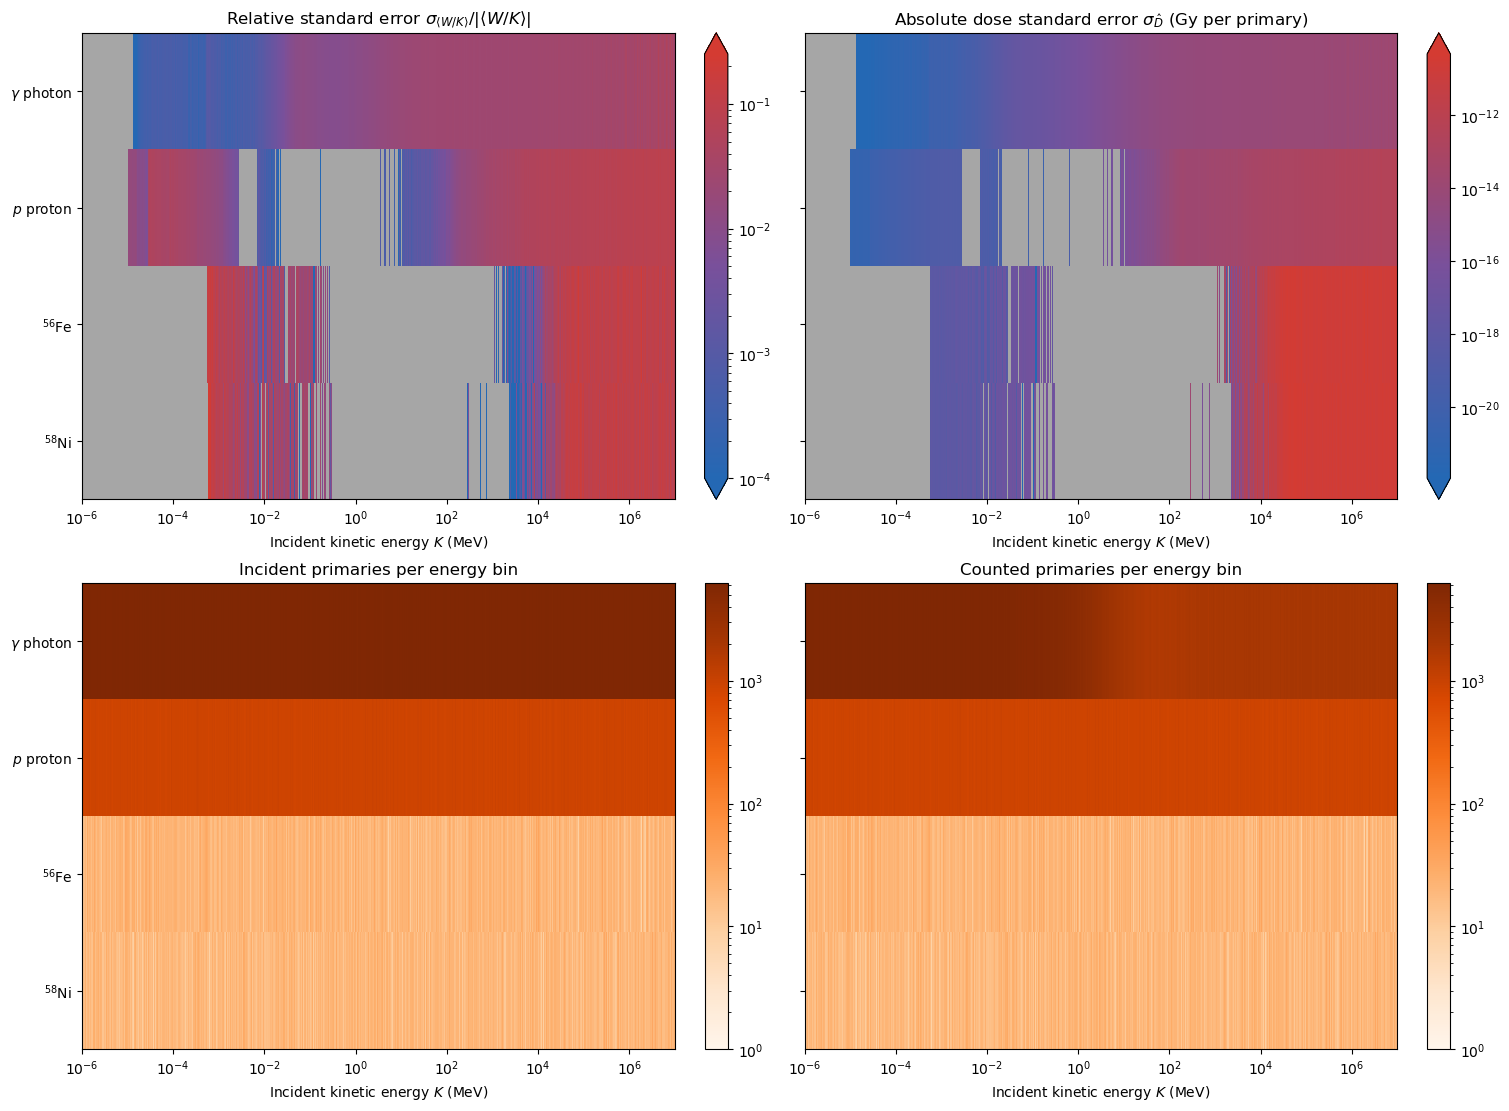

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharey=True, layout="constrained")
plot_sampling_precision(phantom, axes=axes)
plt.show()

### Continue sampling

From the run directory, this command adds up to five adaptive batches:

```bash
atris-build-phantom . --adaptive --batches 5 --threads 3
```

The builder first covers species, then explores missing or unmeasured ranges. With matching-thread timings, it prefers predicted energy-precision improvement per second. Every fifth selection makes a coverage turn. Forecasts and observed timings remain in `batches.json`.

Energy-response uncertainty drives refinement; counting efficiency is exported alongside it. The energy target combines relative tolerance with an absolute dose floor, as described in [refinement and precision](../running-atris/build-phantoms.md#refine-and-inspect). Bins with zero observed deposits remain unresolved.

The post-processing cell shows results after further batches. The equivalent terminal command refreshes exports from completed statistics:

```bash
atris-build-phantom . --postprocess-only
```

## 8. Exports

The run folder contains `water-sphere_response.txt`, `water-sphere_counting.txt` and `water-sphere_sampling.root`, with counts, response arrays, uncertainties and metadata. `water-sphere_sampling-state.json` records coverage and precision. `paths` is the tuple of files written by `phantom.save()`; callers can ignore it when not needed. Saving does not create or change `phantoms.txt`; choose simulation inputs explicitly using [phantom selection and staging](../running-atris/prepare-simulation.md#optionally-select-phantoms). The terminal command also saves `water-sphere_diagnostics.png` and `water-sphere_sampling-precision.png`. `Phantom.read_root(path)` restores the phantom from the ROOT file. JSON records retain runner settings, batch history and progress only. Pilot matrices contain NaNs where estimates are missing. Coverage and precision diagnostics show how far sampling has progressed toward usable tables.

The regular `atris-plot` image combines counting efficiency and deposited fraction, with constant deposited-energy guides. The builder's creation diagnostics show sampling quality.

[Phantom selection and staging](../running-atris/prepare-simulation.md#optionally-select-phantoms) describes the use of completed tables in an atmospheric run. The [spectrum-folding notebook](earth-spectrum-folding.ipynb) explains physical source rates.